# How well do CLIP features predict macaque IT responses, and how much of that comes from training?

| | |
| --- | --- |
| **Question** | How well does a linear map from CLIP ViT-B/32 features predict held-out responses of 168 macaque IT recording sites, compared with the same network with random weights? |
| **Requires** | The MajajHong2015 public data (downloaded by Brain-Score on first use) and the CLIP ViT-B/32 weights from Hugging Face. A GPU makes feature extraction take seconds; on a CPU it takes several minutes. The linear fits take a few minutes on either. |
| **Lessons used** | [2. Your first benchmark](../lessons/02_your_first_benchmark.ipynb), [3. Wrap a PyTorch model](../lessons/03_wrap_a_pytorch_model.ipynb), [5. Layers and regions](../lessons/05_layers_and_regions.ipynb) |

## Background

Neural predictivity is the standard Brain-Score test of whether a model's internal representation resembles a brain region. Features from one model layer are mapped linearly to recorded responses on training images, and the map is tested on held-out images. The data are multi-unit responses from macaque inferior temporal cortex (IT) to 3,200 images of objects on varied backgrounds (Majaj, Hong et al., 2015, *J. Neurosci.*, [doi:10.1523/JNEUROSCI.5181-14.2015](https://doi.org/10.1523/JNEUROSCI.5181-14.2015); public half).

A linear map from tens of thousands of features can fit a lot, so a high correlation alone does not show that the features are brain-like. The control is the same architecture with random weights: whatever it predicts comes from the architecture and the images, not from training.

## Hypothesis

Trained CLIP features predict held-out IT responses better than random-weight features at most recording sites.

## Method

**Data.** The registered benchmark's own loader: IT sites only, responses averaged over repetitions, one value per image and site.

**Features.** `neural_response` presents the images to each subject and records the layer its region map assigns to IT (`encoder.layers.10` for both).

**Map and test.** Partial least squares regression with 25 components, as in the benchmark, fitted on 90% of the images and tested on the other 10%, over 10 splits stratified by object. Each site's score is the Pearson correlation between its predicted and measured held-out responses. Pearson r is 0 for no linear relationship and 1 for a perfect one. The values here are raw correlations, not divided by the data's noise ceiling.

In [1]:
%matplotlib inline
import warnings
from functools import partialmethod
from tqdm.auto import tqdm
import os, tqdm as _tqdm
for _bar in (tqdm, _tqdm.tqdm):                   # notebook and console progress bars
    _bar.__init__ = partialmethod(_bar.__init__, disable=True)
os.environ['BS_INSTALL_DEPENDENCIES'] = 'no'      # requirements are already installed
warnings.filterwarnings('ignore')

import numpy as np
import matplotlib.pyplot as plt
import brainscore
from brainscore_core.streaming_helpers import neural_response
from brainscore_vision.benchmarks.majajhong2015.benchmark import load_assembly

it = load_assembly(average_repetitions=True, region='IT', access='public')
print(it.dims, it.shape)                            # (images, IT sites)

('presentation', 'neuroid') (3200, 168)


In [2]:
features = {}
for name in ('clip-vit-b-32', 'random-vit-b-32'):
    model = brainscore.load_model(name)
    features[name] = neural_response(model, it.stimulus_set, record='IT')
    print(name, features[name].shape)

clip-vit-b-32 (3200, 38400)


random-vit-b-32 (3200, 38400)


The recorded features follow the stimulus set's order; the neural responses are aligned to them by stimulus ID before fitting.

In [3]:
from scipy.stats import pearsonr
from sklearn.cross_decomposition import PLSRegression
from sklearn.model_selection import StratifiedShuffleSplit

order = {s: i for i, s in enumerate(it['stimulus_id'].values)}
Y = np.asarray(it.values)
objects = np.asarray(it['object_name'].values)
splits = list(StratifiedShuffleSplit(n_splits=10, train_size=0.9, random_state=0).split(Y, objects))

def held_out_predictions(assembly):
    X = np.empty((len(Y), assembly.shape[1]))
    X[[order[s] for s in assembly['stimulus_id'].values]] = np.asarray(assembly.values)   # rows in Y's order
    prediction, count = np.zeros_like(Y, dtype=float), np.zeros(len(Y))
    for train, test in splits:
        pls = PLSRegression(n_components=25, scale=False).fit(X[train], Y[train])
        prediction[test] += pls.predict(X[test])
        count[test] += 1
    seen = count > 0
    prediction[seen] /= count[seen, None]
    site_r = np.array([pearsonr(prediction[seen, j], Y[seen, j])[0] for j in range(Y.shape[1])])
    return prediction, seen, site_r

results = {name: held_out_predictions(assembly) for name, assembly in features.items()}
for name, (_, _, site_r) in results.items():
    print(f'{name:16s} median r across sites = {np.median(site_r):.3f}')

clip-vit-b-32    median r across sites = 0.559
random-vit-b-32  median r across sites = 0.298


## Results

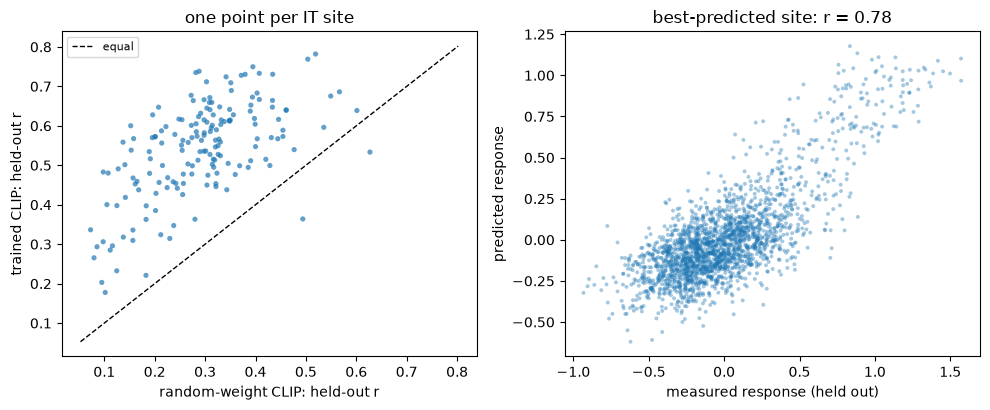

trained better at 99% of 168 sites; median gain +0.262


In [4]:
clip_r, random_r = results['clip-vit-b-32'][2], results['random-vit-b-32'][2]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
ax = axes[0]
ax.scatter(random_r, clip_r, s=14, alpha=0.7, edgecolor='none')
lo, hi = min(random_r.min(), clip_r.min()) - 0.02, max(random_r.max(), clip_r.max()) + 0.02
ax.plot([lo, hi], [lo, hi], 'k--', lw=1, label='equal')
ax.set_xlabel('random-weight CLIP: held-out r'); ax.set_ylabel('trained CLIP: held-out r')
ax.set_title('one point per IT site'); ax.legend(fontsize=8)

best = int(np.argmax(clip_r))
prediction, seen, _ = results['clip-vit-b-32']
ax = axes[1]
ax.scatter(Y[seen, best], prediction[seen, best], s=8, alpha=0.4, edgecolor='none')
ax.set_xlabel('measured response (held out)'); ax.set_ylabel('predicted response')
ax.set_title(f'best-predicted site: r = {clip_r[best]:.2f}')
fig.tight_layout()
plt.show()

print(f'trained better at {np.mean(clip_r > random_r):.0%} of {len(clip_r)} sites; '
      f'median gain {np.median(clip_r - random_r):+.3f}')

The left panel answers the question site by site: points above the diagonal are sites that trained features predict better than random ones. The right panel shows held-out predictions for the best site; it is the most favorable site, so its correlation is an upper bound, not a typical value.

The registered benchmark runs the same procedure with its own splits and divides by the noise ceiling, so its score is on the leaderboard's scale:

In [5]:
for name in ('clip-vit-b-32', 'random-vit-b-32'):
    score = brainscore.score(name, 'MajajHong2015public.IT-pls-unified')
    print(f'{name:16s} benchmark score {float(score):.3f}')

clip-vit-b-32    benchmark score 0.374


random-vit-b-32  benchmark score 0.111


## Conclusion and limits

The result supports the hypothesis. Trained CLIP features predicted held-out IT responses with a median correlation of 0.559 across the 168 sites, against 0.298 for the same network with random weights; trained features were better at 99% of sites, by a median of 0.26. Random features already predict a good part of IT's response, so the training effect is the gap, not the trained value alone. On the benchmark's own scale, divided by the noise ceiling, the scores are 0.374 and 0.111.

Limits: one layer per network, chosen by the region map rather than fitted to these data; one random initialization; the public half of the data. The comparison does not say which aspect of CLIP's training matters; comparing with other trained networks on the same benchmark would.

[Lessons](../lessons/) · [Documentation](../../docs/README.md)